# Crop Recommendation — Entrenamiento del modelo (CRISP-ML(Q))
**Objetivo de negocio:** recomendar el cultivo más adecuado a partir de las condiciones del suelo (N, P, K, pH) y del clima (temperatura, humedad, lluvia).

**Tipo de problema:** clasificación supervisada multiclase (22 cultivos).

**Criterio de éxito (definido en la Fase 1):** F1 macro ≥ 0.95 en el conjunto de prueba y desviación estándar en validación cruzada < 0.02.

## 0. Configuración: librerías y entorno
Todas las importaciones están en esta celda. El notebook funciona en **Google Colab** y en local.

In [1]:
# ===================== Librerías =====================
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

# ¿Estamos en Google Colab?
try:
    from google.colab import files as colab_files
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

FEATURES = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
TARGET = "label"
print("Entorno:", "Google Colab" if EN_COLAB else "local")

Entorno: local


## Fase 1–2: Comprensión de los datos

In [2]:
# Carga del dataset (en Colab pide subir el CSV si no está en el entorno)
CSV = "Crop_recommendation.csv"
if EN_COLAB:
    if not Path(CSV).exists():
        colab_files.upload()  # selecciona Crop_recommendation.csv
    DATA_PATH, MODELS_DIR = Path(CSV), Path("models")
else:
    DATA_PATH, MODELS_DIR = Path("..") / "data" / CSV, Path("..") / "backend" / "models"

df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

(2200, 8)


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   str    
dtypes: float64(4), int64(3), str(1)
memory usage: 137.6 KB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
N,2200.0,50.551818,36.917334,0.000000,21.000000,37.000000,84.250000,140.000000
P,2200.0,53.362727,32.985883,5.000000,28.000000,51.000000,68.000000,145.000000
K,2200.0,48.149091,50.647931,5.000000,20.000000,32.000000,49.000000,205.000000
temperature,2200.0,25.616244,5.063749,8.825675,22.769375,25.598693,28.561654,43.675493
humidity,2200.0,71.481779,22.263812,14.258040,60.261953,80.473146,89.948771,99.981876
ph,2200.0,6.469480,0.773938,3.504752,5.971693,6.425045,6.923643,9.935091
rainfall,2200.0,103.463655,54.958389,20.211267,64.551686,94.867624,124.267508,298.560117


### QA de datos: nulos, duplicados, balance de clases

In [5]:
print("Nulos por columna:\n", df.isna().sum())
print("\nFilas duplicadas:", df.duplicated().sum())
print("\nNúmero de clases:", df['label'].nunique())
df['label'].value_counts()

Nulos por columna:
 N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Filas duplicadas: 0

Número de clases: 22


label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64

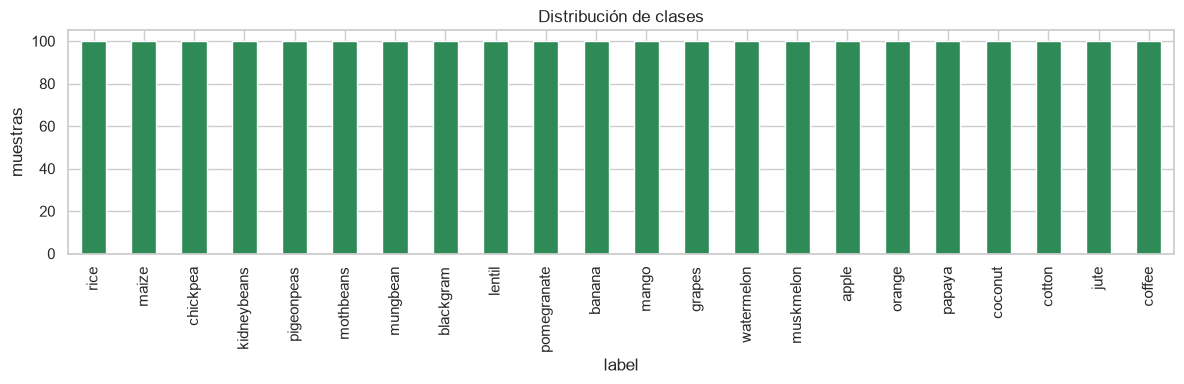

In [6]:
plt.figure(figsize=(12,4))
df['label'].value_counts().plot(kind='bar', color='seagreen')
plt.title('Distribución de clases'); plt.ylabel('muestras'); plt.tight_layout(); plt.show()

### Distribución de las variables

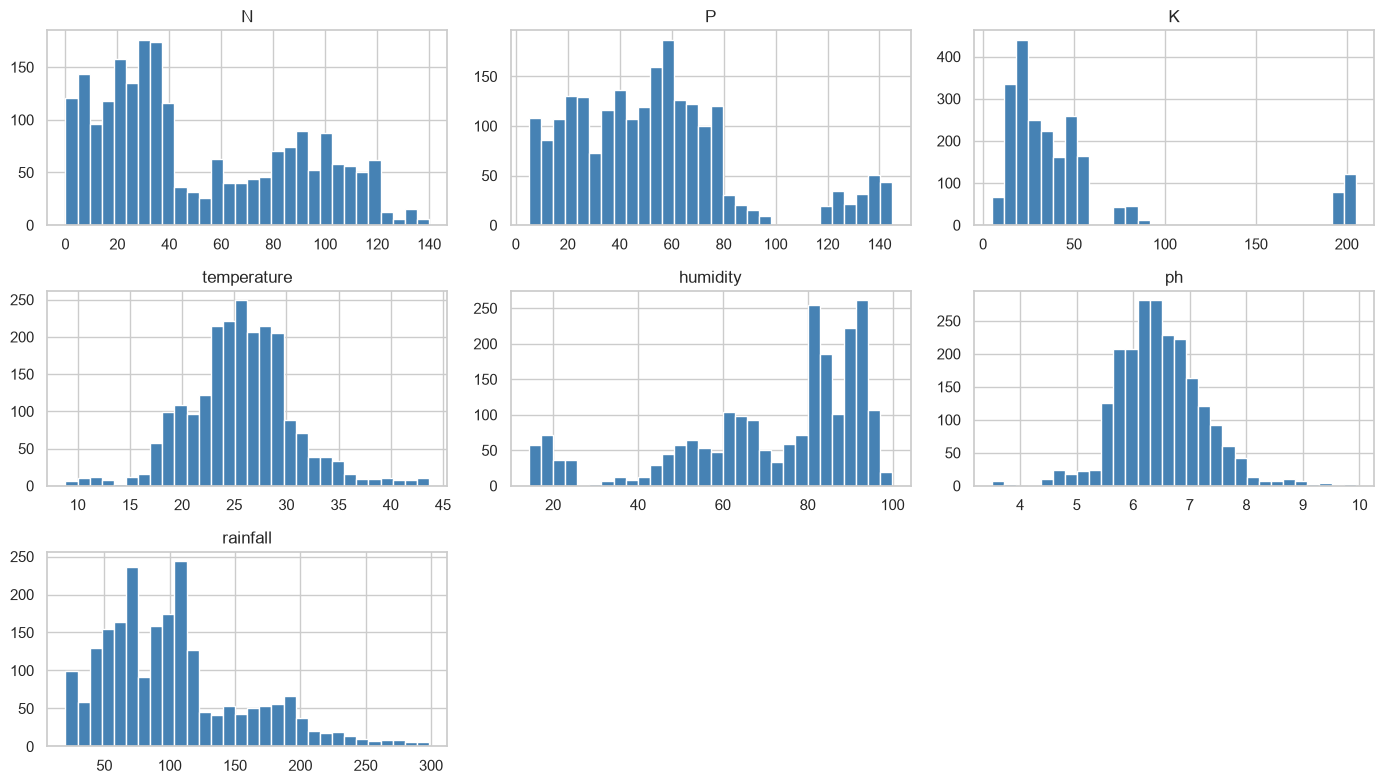

In [7]:
df[FEATURES].hist(bins=30, figsize=(14,8), color="steelblue"); plt.tight_layout(); plt.show()

### Perfil promedio de cada cultivo
Cada fila es un cultivo y cada columna una variable. El **número** es el valor medio de esa variable para ese cultivo y el **color** indica si es alto (rojo) o bajo (azul) comparado con el resto de cultivos (z-score por columna). Sirve para ver de un vistazo qué condiciones distinguen a cada cultivo.

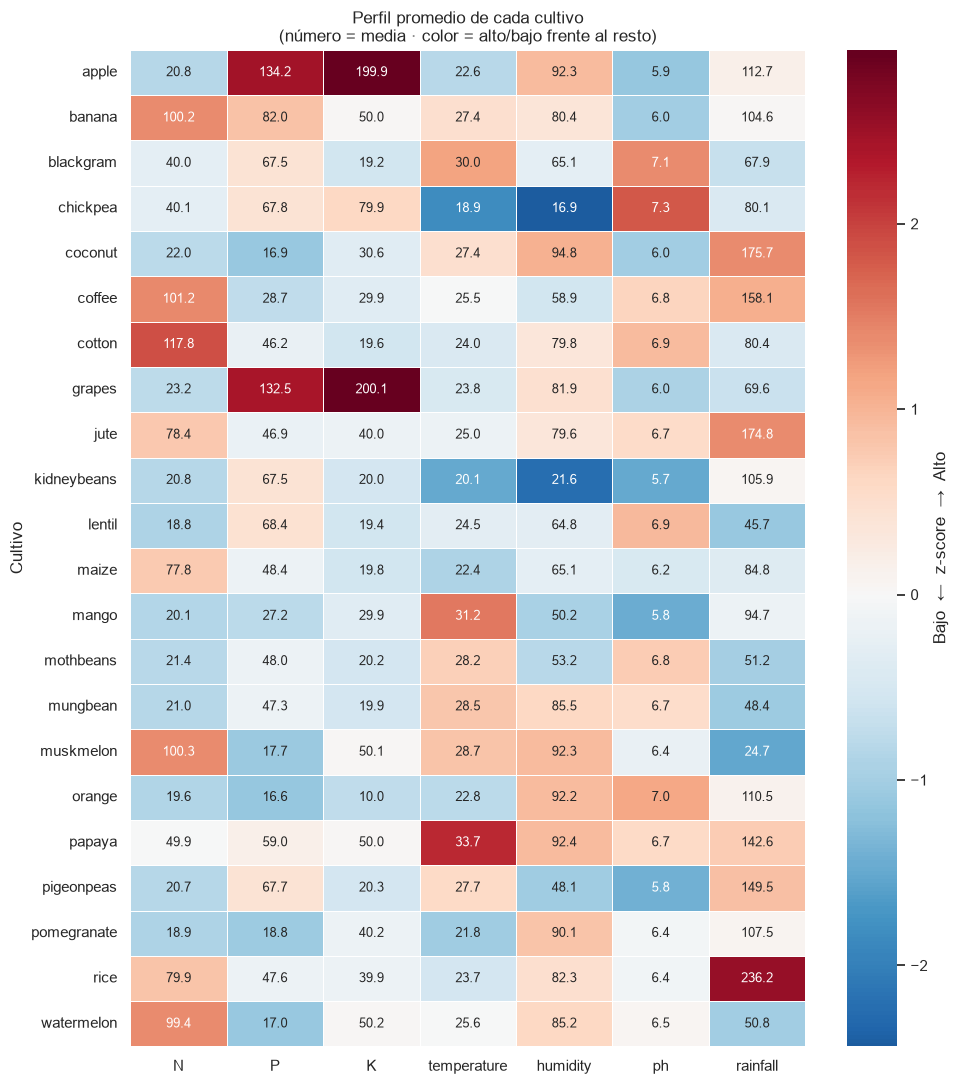

In [8]:
perfil = df.groupby(TARGET)[FEATURES].mean()
z = (perfil - perfil.mean()) / perfil.std()

plt.figure(figsize=(10, 11))
sns.heatmap(z, annot=perfil.round(1), fmt="", cmap="RdBu_r", center=0,
            linewidths=0.6, linecolor="white", annot_kws={"size": 9},
            cbar_kws={"label": "Bajo  ←  z-score  →  Alto"})
plt.title("Perfil promedio de cada cultivo\n(número = media · color = alto/bajo frente al resto)")
plt.xlabel(""); plt.ylabel("Cultivo")
plt.tight_layout(); plt.show()

### Correlaciones

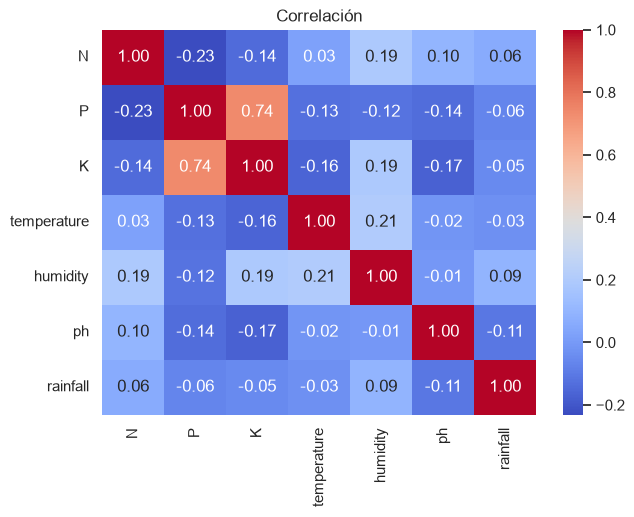

In [9]:
plt.figure(figsize=(7,5))
sns.heatmap(df[FEATURES].corr(), annot=True, fmt='.2f', cmap='coolwarm'); plt.title('Correlación'); plt.show()

**Observaciones:** P y K tienen una correlación alta (≈0.74), impulsada sobre todo por las uvas y las manzanas, que necesitan mucho de ambos. Hay valores atípicos en K, P y rainfall, pero son **propios del dominio** (cultivos concretos), no errores, así que se conservan.

In [10]:
outliers = {}
for f in FEATURES:
    q1, q3 = df[f].quantile([.25,.75]); iqr = q3-q1
    outliers[f] = int(((df[f] < q1-1.5*iqr) | (df[f] > q3+1.5*iqr)).sum())
outliers

{'N': 0,
 'P': 138,
 'K': 200,
 'temperature': 86,
 'humidity': 30,
 'ph': 57,
 'rainfall': 100}

## Fase 3: Preparación de los datos
Separación 80/20 **estratificada** y escalado (StandardScaler dentro de un Pipeline para evitar *data leakage*).

In [11]:
X, y = df[FEATURES], df['label']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_train.shape, X_test.shape

((1760, 7), (440, 7))

## Fase 4: Ingeniería del modelo — comparación de algoritmos (CV de 5 folds)

In [12]:
candidates = {
    'LogisticRegression': LogisticRegression(max_iter=2000),
    'KNN': KNeighborsClassifier(),
    'SVC': SVC(),
    'DecisionTree': DecisionTreeClassifier(random_state=42),
    'GaussianNB': GaussianNB(),
    'RandomForest': RandomForestClassifier(random_state=42),
    'GradientBoosting': GradientBoostingClassifier(random_state=42),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for name, est in candidates.items():
    pipe = Pipeline([('scaler', StandardScaler()), ('clf', est)])
    s = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='f1_macro', n_jobs=-1)
    rows.append({'modelo': name, 'f1_cv_mean': s.mean(), 'f1_cv_std': s.std()})
results = pd.DataFrame(rows).sort_values('f1_cv_mean', ascending=False).reset_index(drop=True)
results

,modelo,f1_cv_mean,f1_cv_std
0,GaussianNB,0.994871,0.004192
1,RandomForest,0.992566,0.005918
2,GradientBoosting,0.986861,0.003575
3,DecisionTree,0.985223,0.006794
4,SVC,0.978803,0.010624
5,LogisticRegression,0.967824,0.006765
6,KNN,0.965011,0.012439


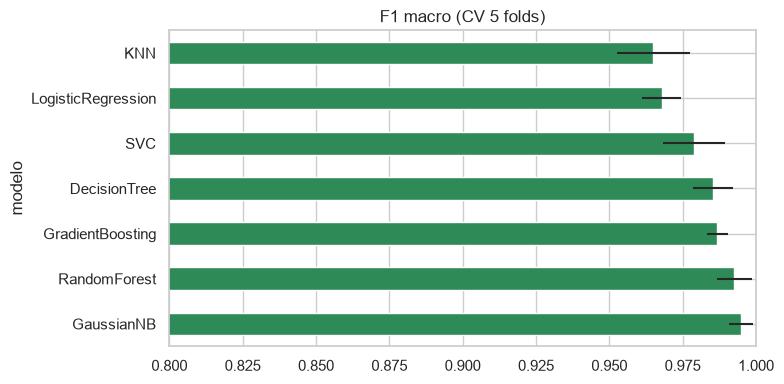

In [13]:
results.plot.barh(x='modelo', y='f1_cv_mean', xerr='f1_cv_std', legend=False, figsize=(8,4), color='seagreen')
plt.xlim(0.8, 1.0); plt.title('F1 macro (CV 5 folds)'); plt.tight_layout(); plt.show()

### Ajuste de hiperparámetros (Random Forest)
GaussianNB (0.995) y Random Forest (0.993) quedan empatados en F1 de CV: la diferencia es menor que su desviación estándar. Se elige **Random Forest** porque:
- no supone que las variables sean independientes ni normales (P y K están correlacionadas, ρ≈0.74, lo que viola el supuesto de Naive Bayes);
- es robusto frente a los valores atípicos que se observaron en P, K y rainfall;
- da **importancia de variables** (explicabilidad para el usuario final);
- con GridSearch sube a 0.995 y sus probabilidades (`predict_proba`) sirven como confianza de la recomendación.

In [14]:
grid = GridSearchCV(
    Pipeline([('scaler', StandardScaler()), ('clf', RandomForestClassifier(random_state=42))]),
    {'clf__n_estimators': [100, 200, 300], 'clf__max_depth': [None, 10, 20], 'clf__min_samples_split': [2, 5]},
    cv=cv, scoring='f1_macro', n_jobs=-1)
grid.fit(X_train, y_train)
print('Mejores parámetros:', grid.best_params_)
print('F1 CV:', round(grid.best_score_, 4))

Mejores parámetros: {'clf__max_depth': None, 'clf__min_samples_split': 5, 'clf__n_estimators': 200}
F1 CV: 0.9954


## Fase 5: Evaluación (Quality Assurance del modelo)

In [15]:
best = grid.best_estimator_
y_pred = best.predict(X_test)
print('Accuracy:', round(accuracy_score(y_test, y_pred), 4))
print('F1 macro:', round(f1_score(y_test, y_pred, average='macro'), 4))
print(classification_report(y_test, y_pred, digits=3))

Accuracy: 0.9955
F1 macro: 0.9955
              precision    recall  f1-score   support

       apple      1.000     1.000     1.000        20
      banana      1.000     1.000     1.000        20
   blackgram      1.000     0.950     0.974        20
    chickpea      1.000     1.000     1.000        20
     coconut      1.000     1.000     1.000        20
      coffee      1.000     1.000     1.000        20
      cotton      1.000     1.000     1.000        20
      grapes      1.000     1.000     1.000        20
        jute      0.952     1.000     0.976        20
 kidneybeans      1.000     1.000     1.000        20
      lentil      1.000     1.000     1.000        20
       maize      0.952     1.000     0.976        20
       mango      1.000     1.000     1.000        20
   mothbeans      1.000     1.000     1.000        20
    mungbean      1.000     1.000     1.000        20
   muskmelon      1.000     1.000     1.000        20
      orange      1.000     1.000     1.000    

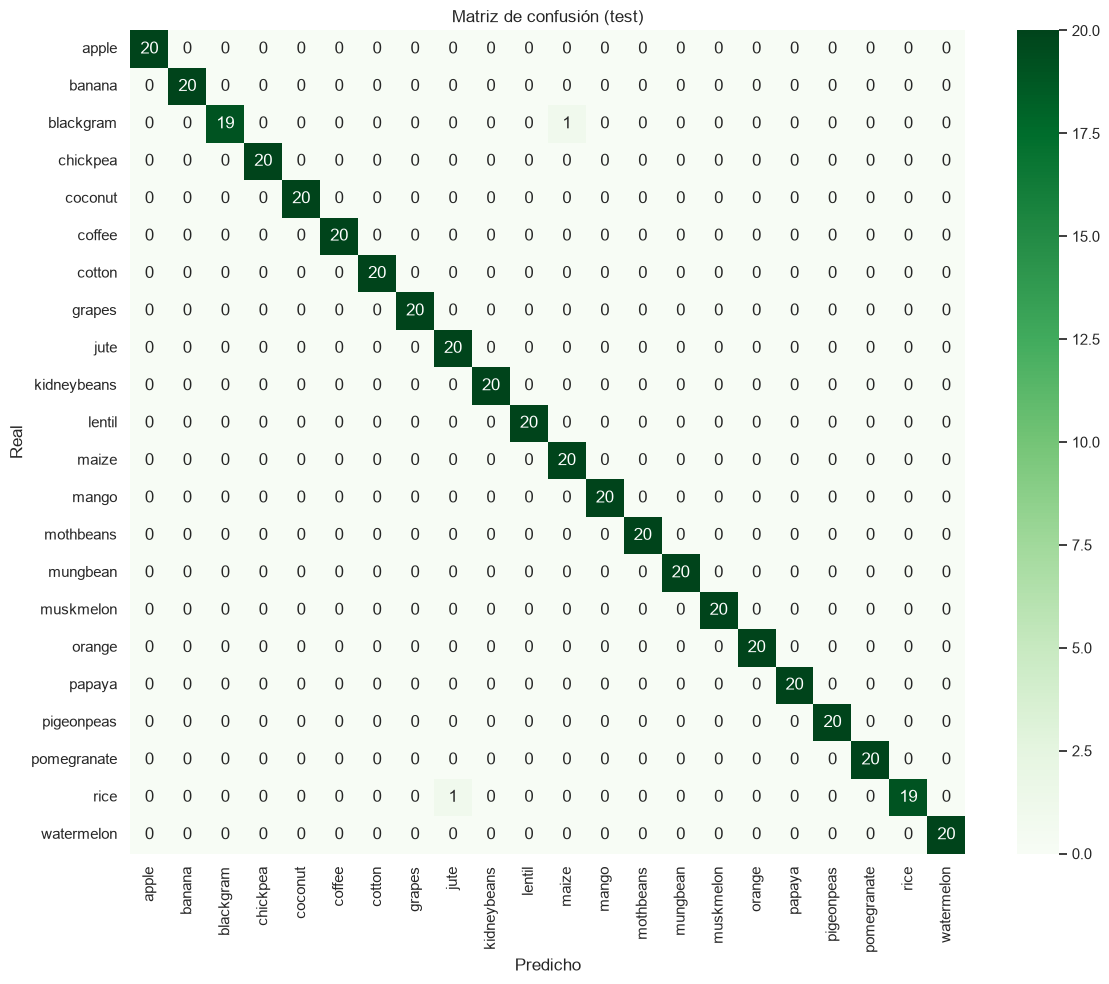

In [16]:
cm = confusion_matrix(y_test, y_pred, labels=best.classes_)
plt.figure(figsize=(12,10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=best.classes_, yticklabels=best.classes_)
plt.xlabel('Predicho'); plt.ylabel('Real'); plt.title('Matriz de confusión (test)'); plt.tight_layout(); plt.show()

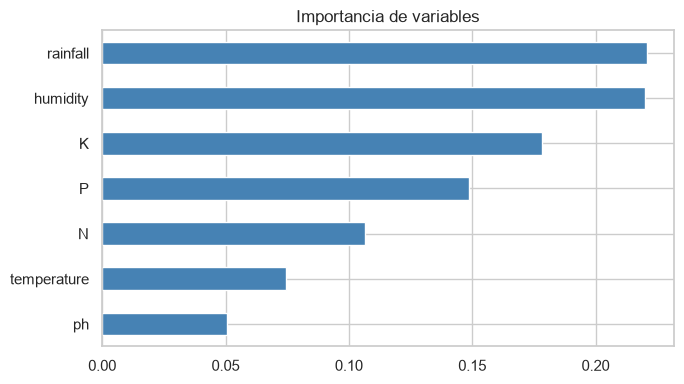

In [17]:
imp = pd.Series(best.named_steps['clf'].feature_importances_, index=FEATURES).sort_values()
imp.plot.barh(color='steelblue', figsize=(7,4)); plt.title('Importancia de variables'); plt.tight_layout(); plt.show()

### Chequeo de sobreajuste: rendimiento en train frente a test

In [18]:
print('Train accuracy:', round(best.score(X_train, y_train), 4))
print('Test accuracy :', round(best.score(X_test, y_test), 4))

Train accuracy: 1.0
Test accuracy : 0.9955


**Conclusión de QA:** el modelo supera el criterio de éxito (F1 macro ≥ 0.95) y su varianza en CV es baja. La alta precisión se explica porque cada cultivo ocupa una región muy definida en el espacio de variables (se ve en el mapa de perfiles por cultivo). Los pocos errores que hay se dan entre cultivos con condiciones parecidas. **Limitación:** el dataset procede de condiciones agroclimáticas de la India, así que fuera de esa región el modelo debe validarse y re-entrenarse (por eso la API ofrece los endpoints de carga de CSV y re-entrenamiento).

## Fase 6: Exportar el modelo base

In [19]:
MODELS_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(best, MODELS_DIR / "notebook_baseline.joblib")
print("Modelo guardado en", MODELS_DIR / "notebook_baseline.joblib")
if EN_COLAB:
    colab_files.download(str(MODELS_DIR / "notebook_baseline.joblib"))

Modelo guardado en ..\backend\models\notebook_baseline.joblib
